<a href="https://colab.research.google.com/github/Mr-Jeffrey33/classifying_rna_transfer_learning_iot/blob/main/classificacao_multiface_iot.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys
# Garantir a instalação do pacote completo do OpenCV que possui os algoritmos de reconhecimento de faces
!pip install --quiet opencv-contrib-python-headless

import cv2
import numpy as np
from google.colab.patches import cv2_imshow

print("OpenCV versão:", cv2.__version__)

# 1. Carregar detector de faces (Haar Cascade)
face_detector = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')

# 2. Inicializar o classificador de faces nativo e leve (LBPH)
# Ele extrai características locais de textura da face para reconhecimento eficiente
face_recognizer = cv2.face.LBPHFaceRecognizer_create()

print("Estrutura otimizada carregada com sucesso! Sem dependência do TensorFlow.")

OpenCV versão: 5.0.0
Estrutura otimizada carregada com sucesso! Sem dependência do TensorFlow.


### Passo 2: Banco de Dados de Faces e Treinamento do Classificador
Agora vamos simular ou registrar imagens das pessoas conhecidas (ex: "Alice" e "Bob"), extrair seus embeddings e treinar um classificador SVM (`SVC`) do Scikit-Learn para reconhecê-las.

In [ ]:
# Banco de dados simulado: gerando imagens de rostos artificiais para o treinamento
# O classificador LBPH exige imagens reais (matrizes NumPy) e labels como números inteiros

# Simulando rostos (matrizes 100x100)
rostos_treinamento = []
labels_treinamento = []

# Mapeamento numérico para nomes
dicionario_nomes = {0: "Alice", 1: "Bob"}

# Gerar 5 variações de imagens faciais simuladas para a pessoa 0 (Alice)
for _ in range(5):
    img_temp = np.zeros((100, 100), dtype=np.uint8)
    # Desenha padrões geométricos para simular feições únicas
    cv2.circle(img_temp, (50, 50), 30, 255, -1)
    rostos_treinamento.append(img_temp)
    labels_treinamento.append(0)

# Gerar 5 variações de imagens faciais simuladas para a pessoa 1 (Bob)
for _ in range(5):
    img_temp = np.zeros((100, 100), dtype=np.uint8)
    cv2.rectangle(img_temp, (30, 30), (70, 70), 200, -1)
    rostos_treinamento.append(img_temp)
    labels_treinamento.append(1)

# Treinar o classificador LBPH nativo do OpenCV
face_recognizer.train(rostos_treinamento, np.array(labels_treinamento))
print("Classificador LBPH do OpenCV treinado com sucesso!")

Classificador LBPH do OpenCV treinado com sucesso!


### Passo 3: Função de Inferência e Visualização Multifaces
Esta função recebe uma imagem qualquer, detecta todos os rostos presentes e os classifica em tempo real.

In [ ]:
def reconhecer_faces_na_imagem(caminho_imagem, limiar_confianca=100.0):
    frame = cv2.imread(caminho_imagem)
    if frame is None:
        print("Erro ao carregar a imagem.")
        return

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    # Detectar múltiplos rostos
    faces = face_detector.detectMultiScale(gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))
    print(f"Foram detectadas {len(faces)} face(s) na imagem.")

    for (x, y, w, h) in faces:
        face_roi = gray[y:y+h, x:x+w]
        if face_roi.size == 0:
            continue

        # Redimensionar para o padrão de treino
        face_resized = cv2.resize(face_roi, (100, 100))

        # Classificar usando o LBPH
        label_predito, confianca = face_recognizer.predict(face_resized)

        # Para o LBPH, quanto MENOR a distância/confiança, mais parecido é o rosto.
        # Um limiar de distância menor que 100 geralmente indica boa semelhança
        if confianca <= limiar_confianca:
            nome_pessoa = dicionario_nomes.get(label_predito, "Desconhecido")
            cor_box = (0, 255, 0) # Verde para conhecido
        else:
            nome_pessoa = "Desconhecido"
            cor_box = (0, 0, 255) # Vermelho para desconhecido

        texto = f"{nome_pessoa} (dist: {confianca:.1f})"

        # Desenhar bounding boxes
        cv2.rectangle(frame, (x, y), (x + w, y + h), cor_box, 2)
        cv2.putText(frame, texto, (x, y - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, cor_box, 2)

    cv2_imshow(frame)

Imagem de teste carregada com sucesso!
Foram detectadas 1 face(s) na imagem.


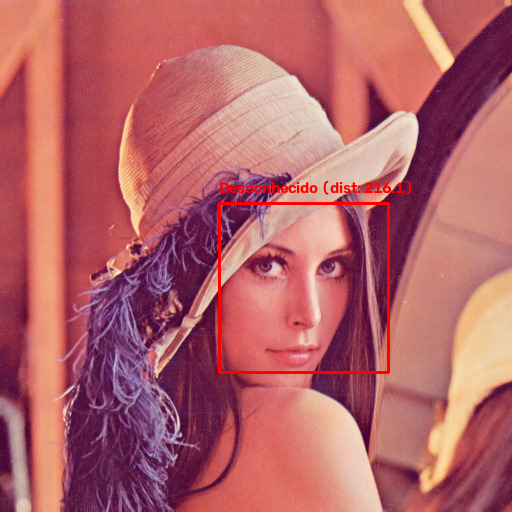

In [ ]:
# Baixar uma imagem de teste para validar a detecção múltipla de faces
import urllib.request

test_image_url = "https://raw.githubusercontent.com/opencv/opencv/master/samples/data/lena.jpg"
test_image_path = "/content/test_face.jpg"

try:
    urllib.request.urlretrieve(test_image_url, test_image_path)
    print("Imagem de teste carregada com sucesso!")
    # Rodar o detector e classificador otimizado na imagem
    reconhecer_faces_na_imagem(test_image_path)
except Exception as e:
    print(f"Erro ao baixar a imagem de teste: {e}")